# Radar de desabastecimiento de medicamentos en Colombia

**Pregunta:** ¿podemos anticipar qué medicamentos tendrán que importarse de emergencia el próximo año?

Cuando un medicamento falta en Colombia, el INVIMA autoriza importarlo como **medicamento vital no disponible**. Ese registro público es el mejor termómetro que existe del desabastecimiento. Este análisis lo cruza con el **Código Único de Medicamentos (CUM)** —todas las presentaciones con registro sanitario, con sus fechas de activación e inactivación— para reconstruir cómo estaba el mercado de cada molécula en cualquier fecha pasada y entrenar un modelo con validación temporal.

| Fuente | Dataset en datos.gov.co | Filas |
|---|---|---|
| Medicamentos vitales no disponibles (INVIMA) | `sdmr-tfmf` | ~11.000 autorizaciones, 2018–2026 |
| CUM vigentes (INVIMA) | `i7cb-raxc` | ~157.000 presentaciones |
| CUM vencidos (INVIMA) | `vwwf-4ftk` | ~153.000 presentaciones |

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import load_cum, load_vitales
from normalize import normalize, split_combo

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
ROJO, GRIS = "#c8102e", "#9a9a9a"
FIG = Path.cwd().parent / "reports" / "figures"

## 1. Los datos y la normalización de nombres

Los dos sistemas escriben las moléculas de forma distinta (`CLORURO DE POTASIO` vs `POTASIO CLORURO`, sales e hidratos, `EQUIVALENTE A …`). La función `normalize` lleva ambos a una forma canónica.

In [2]:
ejemplos = ["CLORURO DE POTASIO", "POTASIO CLORURO", "LIDOCAÍNA CLORHIDRATO", "CLORHIDRATO DE METFORMINA",
            "SELENATO DE SODIO EQUIVALENTE A SELENIO", "ELEXACAFTOR / TEZACAFTOR / IVACAFTOR"]
pd.DataFrame({"original": ejemplos, "canónico": [", ".join(split_combo(e)) for e in ejemplos]})

,original,canónico
0,CLORURO DE POTASIO,CLORURO POTASIO
1,POTASIO CLORURO,CLORURO POTASIO
2,LIDOCAÍNA CLORHIDRATO,LIDOCAINA
3,CLORHIDRATO DE METFORMINA,METFORMINA
4,SELENATO DE SODIO EQUIVALENTE A SELENIO,SELENIO
5,ELEXACAFTOR / TEZACAFTOR / IVACAFTOR,"ELEXACAFTOR, TEZACAFTOR, IVACAFTOR"


In [3]:
vit = load_vitales()
cum = load_cum()
raw = pd.read_csv("../data/raw/vitales_no_disponibles.csv", dtype=str)
raw["fecha"] = pd.to_datetime(raw["fecha_de_autorizaci_n"], errors="coerce").dt.tz_localize(None)
print(f"{len(raw):,} autorizaciones · {vit['molecula'].nunique()} moléculas en la lista · {cum['molecula'].nunique():,} moléculas en el CUM")
con_registro = set(vit["molecula"]) & set(cum["molecula"])
print(f"{len(con_registro)} moléculas de la lista SÍ tienen registro sanitario en Colombia")

11,155 autorizaciones · 585 moléculas en la lista · 8,894 moléculas en el CUM
196 moléculas de la lista SÍ tienen registro sanitario en Colombia


## 2. Exploración: el desabastecimiento va en aumento

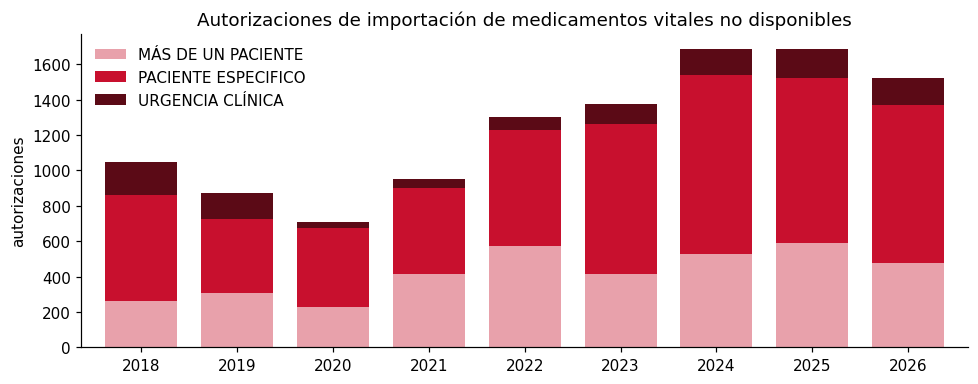

año,2018,2019,2020,2021,2022,2023,2024,2025,2026
total,1047,871,710,949,1302,1377,1689,1689,1521


In [4]:
anual = raw.groupby([raw["fecha"].dt.year.rename("año"), "tipo_de_solicitud"]).size().unstack(fill_value=0)
ax = anual.plot(kind="bar", stacked=True, figsize=(9, 3.6), color=["#e8a1ab", ROJO, "#5b0a16"], width=0.75)
ax.set_title("Autorizaciones de importación de medicamentos vitales no disponibles"); ax.set_xlabel(""); ax.set_ylabel("autorizaciones")
ax.legend(title="", frameon=False); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG / "autorizaciones_por_anio.png"); plt.show()
anual.sum(axis=1).to_frame("total").T

2026 llega solo hasta septiembre y ya está cerca del total de 2025: el ritmo se sostiene en el nivel más alto de la serie.

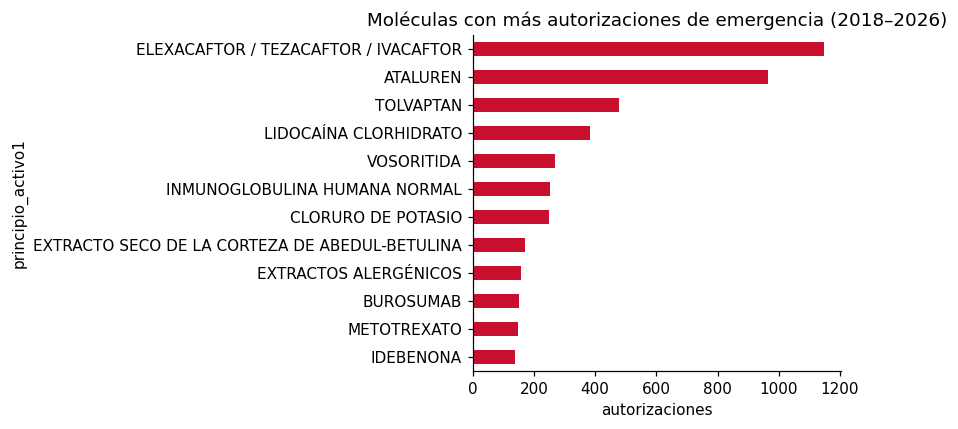

In [5]:
top = raw["principio_activo1"].str.strip().str.upper().value_counts().head(12)[::-1]
ax = top.plot(kind="barh", figsize=(8, 4), color=ROJO)
ax.set_title("Moléculas con más autorizaciones de emergencia (2018–2026)"); ax.set_xlabel("autorizaciones")
plt.tight_layout(); plt.savefig(FIG / "top_moleculas.png"); plt.show()

In [6]:
raw["diagnostico_cie_1no_reporta"].str.strip().str.upper().value_counts().head(10).to_frame("autorizaciones")

,autorizaciones
diagnostico_cie_1no_reporta,
NO REPORTADO,1448
DISTROFIA MUSCULAR,1202
FIBROSIS QUISTICA CON MANIFESTACIONES PULMONARES,642
"FIBROSIS QUISTICA, SIN OTRA ESPECIFICACION",501
"RIÑON POLIQUISTICO, TIPO ADULTO",387
ALERGIA NO ESPECIFICADA,374
ACONDROPLASIA,267
EPIDERMOLISIS BULLOSA DISTROFICA,160
LEUCEMIA LINFOBLASTICA AGUDA,156


## 3. El problema como aprendizaje supervisado

Para cada **fecha de corte** D (31 de diciembre de 2018 a 2024) y cada molécula con registro en el CUM se calculan variables usando **solo información disponible hasta D**:

- **Mercado (CUM):** presentaciones y titulares activos, concentración (índice HHI), proporción importada, registros perdidos y nuevos en 12–24 meses, años en el mercado, grupo ATC y vía.
- **Historial:** autorizaciones de emergencia en 12 y 24 meses, total histórico, meses desde la última.
- **Contagio terapéutico:** desabastecimientos recientes de *otras* moléculas del mismo grupo ATC.

**Etiqueta:** ¿la molécula aparece en la lista de vitales no disponibles en los 12 meses siguientes a D?

In [7]:
panel = pd.read_parquet("../data/processed/panel.parquet")
lab = panel[panel["corte"] < "2026-01-01"]
lab.groupby("corte").agg(moleculas=("molecula", "size"), positivos=("y", "sum"), tasa=("y", "mean")).style.format({"tasa": "{:.2%}"})

,moleculas,positivos,tasa
corte,,,
2018-12-31 00:00:00,8284,48,0.58%
2019-12-31 00:00:00,8340,55,0.66%
2020-12-31 00:00:00,8427,63,0.75%
2021-12-31 00:00:00,8544,69,0.81%
2022-12-31 00:00:00,8595,66,0.77%
2023-12-31 00:00:00,8719,65,0.75%
2024-12-31 00:00:00,8813,63,0.71%


In [8]:
pos = lab[lab["y"] == 1]
print(f"{(pos['vitales_historico'] > 0).mean():.0%} de las moléculas que entran a la lista ya habían estado antes en ella.")
lab.groupby("y")[["presentaciones_activas", "titulares_activos", "share_importadas", "hhi_titulares", "vitales_12m_mismo_atc3"]].mean().round(2)

77% de las moléculas que entran a la lista ya habían estado antes en ella.


,presentaciones_activas,titulares_activos,share_importadas,hhi_titulares,vitales_12m_mismo_atc3
y,,,,,
0,5.58,0.96,0.2,0.94,2.86
1,27.72,4.24,0.5,0.68,8.78


**Hallazgo clave:** el desabastecimiento es crónico. Tres de cada cuatro moléculas que necesitarán importación de emergencia el próximo año ya estuvieron en la lista. Por eso cualquier modelo debe compararse contra una línea base de **persistencia** —y por eso lo interesante es detectar los **casos nuevos**.

**Segundo hallazgo, contraintuitivo:** las moléculas que entran a la lista tienen *más* titulares activos (≈5 frente a ≈2,7) y mercados *menos* concentrados. No faltan sobre todo los medicamentos raros, sino genéricos esenciales de alto uso y bajo margen (lidocaína, cloruro de potasio, metotrexato), un patrón conocido de desabastecimiento de genéricos.

**Tercer hallazgo:** el contagio por clase terapéutica es real. Si otras moléculas del mismo grupo ATC estuvieron en la lista el último año, la tasa de entrada se triplica (≈3,0 % frente a ≈0,95 %).

## 4. Modelos y validación temporal de origen móvil

Para cada año de prueba se entrena **solo con cortes anteriores** (sin mirar el futuro). Se comparan regresión logística, gradient boosting (`HistGradientBoostingClassifier`) y su ensamble contra la línea base.

In [9]:
m = json.loads(Path("../reports/metricas.json").read_text())
prom = pd.DataFrame(m["validacion_movil"]["promedio"]).T
prom.rename(index={"linea_base_persistencia": "línea base (persistencia)"})[["roc_auc", "average_precision", "precision_at_20", "recall_at_100", "auc_casos_nuevos"]]

,roc_auc,average_precision,precision_at_20,recall_at_100,auc_casos_nuevos
línea base (persistencia),0.8990,0.6079,0.8125,0.7492,0.5000
regresion_logistica,0.9462,0.5748,0.7875,0.7452,0.7440
gradient_boosting,0.9402,0.5137,0.7125,0.7802,0.7172
ensamble,0.9460,0.6015,0.7875,0.7760,0.7429


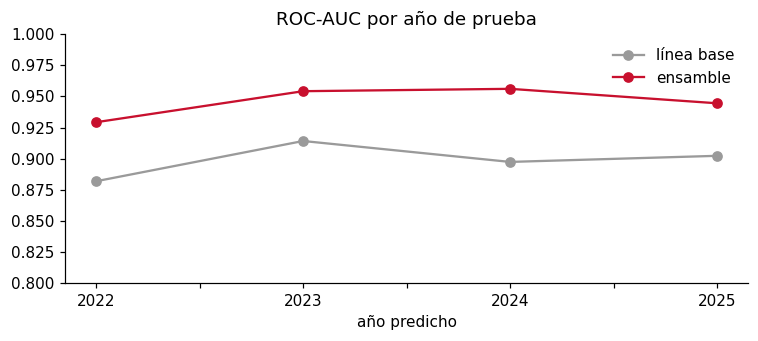

In [10]:
pl = {f: pd.DataFrame(v).T["roc_auc"] for f, v in m["validacion_movil"]["pliegues"].items()}
ax = pd.DataFrame(pl).T[["linea_base_persistencia", "ensamble"]].rename(columns={"linea_base_persistencia": "línea base", "ensamble": "ensamble"}).plot(
    marker="o", figsize=(7, 3.2), color=[GRIS, ROJO])
ax.set_title("ROC-AUC por año de prueba"); ax.set_ylim(0.8, 1); ax.set_xlabel("año predicho"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "auc_por_anio.png"); plt.show()

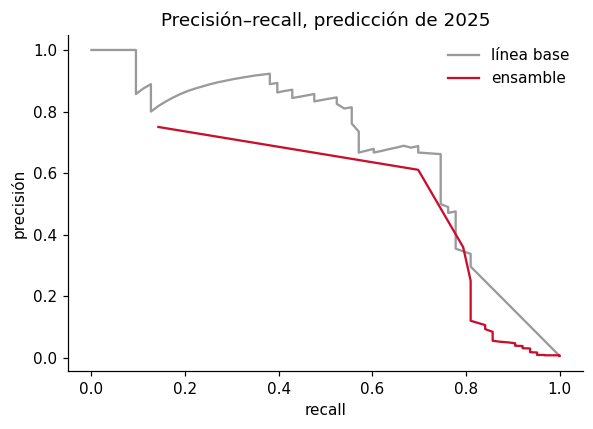

In [11]:
pr_m, pr_b = pd.DataFrame(m["pr_modelo"]), pd.DataFrame(m["pr_linea_base"])
plt.figure(figsize=(5.5, 4))
plt.plot(pr_b["recall"], pr_b["precision"], color=GRIS, label="línea base"); plt.plot(pr_m["recall"], pr_m["precision"], color=ROJO, label="ensamble")
plt.xlabel("recall"); plt.ylabel("precisión"); plt.title("Precisión–recall, predicción de 2025"); plt.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "precision_recall_2025.png"); plt.show()

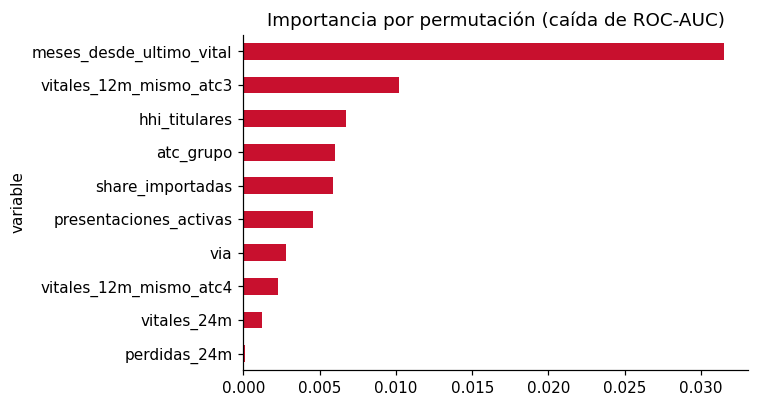

In [12]:
imp = pd.DataFrame(m["importancia"]).set_index("variable")["importancia"].head(10)[::-1]
ax = imp.plot(kind="barh", figsize=(7, 3.8), color=ROJO); ax.set_title("Importancia por permutación (caída de ROC-AUC)")
plt.tight_layout(); plt.savefig(FIG / "importancia.png"); plt.show()

**Lectura honesta de los resultados**

- El ensamble supera a la línea base en ROC-AUC (≈0,95 vs ≈0,90) y en recall dentro del top 100: ordena mejor la lista completa.
- En precisión del top 20 la persistencia es casi imbatible: las moléculas que ya están en crisis lo siguen estando.
- El aporte real del modelo está en los **casos nuevos** (sin historial): ahí la línea base no puede distinguir nada (AUC 0,5) y el modelo llega a ≈0,74 usando la estructura del mercado (titulares y presentaciones), la dependencia de importaciones y el contagio dentro del grupo terapéutico. Con solo ~15 casos nuevos por año, la precisión absoluta sigue siendo baja: sirve para **priorizar vigilancia**, no para decidir.

## 5. Radar actual: riesgo para octubre de 2026 – septiembre de 2027

In [13]:
rk = pd.read_parquet("../data/processed/ranking_actual.parquet").sort_values("riesgo", ascending=False)
rk = rk[(rk["presentaciones_activas"] > 0) | (rk["vitales_historico"] > 0)]
cols = ["molecula", "atc", "riesgo", "vitales_12m", "presentaciones_activas", "titulares_activos", "share_importadas"]
print("Mayor riesgo total"); display(rk[cols].head(10))
print("Mayor riesgo SIN historial en la lista (candidatos nuevos)"); display(rk[rk["vitales_historico"] == 0][cols].head(10))

Mayor riesgo total


,molecula,atc,riesgo,vitales_12m,presentaciones_activas,titulares_activos,share_importadas
7491,LIDOCAINA,N01BB52,0.998117,4.532599,4.927254,25.0,0.204380
6418,ESTIRIPENTOL,N03AX17,0.998060,2.639057,1.609438,2.0,1.000000
4798,BUPIVACAINA,N01BB01,0.998004,3.713572,2.397895,3.0,0.400000
4333,ATOMOXETINA,N06BA09,0.997948,1.609438,3.526361,1.0,0.000000
4385,AZUL METILENO,V03AB17,0.997892,2.772589,1.098612,2.0,0.500000
7691,METOTREXATO,L01BA01,0.997836,2.944439,3.988984,6.0,1.000000
5309,CITARABINA,L01BC01,0.997779,2.197225,1.609438,2.0,1.000000
8848,VOLANESORSEN,C10AX18,0.997723,3.688879,0.693147,1.0,1.000000
5886,DESMOPRESINA,H01BA02,0.997667,0.693147,2.302585,3.0,0.000000
5531,CLORURO POTASIO,A07CA99,0.997611,3.871201,5.765191,26.0,0.251572


Mayor riesgo SIN historial en la lista (candidatos nuevos)


,molecula,atc,riesgo,vitales_12m,presentaciones_activas,titulares_activos,share_importadas
7665,METILFENIDATO,N06BA04,0.983472,0.0,2.944439,5.0,0.888889
7990,OXALIPLATINO,L01XA03,0.983416,0.0,3.258097,7.0,1.000000
7153,IBRUTINIB,L01XE27,0.983360,0.0,2.890372,3.0,1.000000
6768,FUROSEMIDA,C03CA01,0.983360,0.0,3.637586,9.0,0.162162
8083,PEGFILGRASTIM,L03AA13,0.983303,0.0,1.098612,2.0,1.000000
7972,ONDANSETRON,A04AA01,0.982966,0.0,3.610918,11.0,0.777778
4591,BILASTINA,R06AX29,0.982741,0.0,4.343805,8.0,1.000000
8692,TOPIRAMATO,N03AX11,0.981954,0.0,2.564949,3.0,1.000000
5628,COLINA COMPOSICION FENOFIBRATO LOS PELLETS,C10AB05,0.981673,0.0,1.386294,1.0,1.000000
3550,ACIDO FENOFIBRICO,C10AB51,0.981561,0.0,3.828641,5.0,0.333333


## 6. Limitaciones y siguientes pasos

- La lista de vitales no disponibles es un **proxy**: mide importaciones autorizadas, no todo el desabastecimiento (por ejemplo, faltantes que se resuelven sin importar).
- El CUM no trae volúmenes de venta; el tamaño real del mercado de cada molécula queda fuera. Cruzar con SISMED (precios y unidades) es el siguiente paso natural.
- Unas 24.000 presentaciones inactivas no tienen fecha de inactivación y se excluyen de los conteos.
- Con pocos positivos nuevos por año, las métricas de casos nuevos tienen alta varianza entre pliegues.